# Decisión sobre el frente de Pareto + cuadre del flujo de plantas

Este notebook hace dos cosas con el **modelo base nuevo** (`modelo_base.py`):

1. **Vista de la decisión** (`decision_a_posteriori`): sobre el frente de Pareto ya calculado muestra qué punto eligió cada método
   — **suma ponderada normalizada**, **TOPSIS**, **precio del carbono** (si defines uno) y la **rodilla** — y por qué
   (puntos soportados, rectas de la suma ponderada, distancias de TOPSIS, sensibilidad al peso).
2. **Cuadre del flujo** de cada punto elegido: `compra → bodega → plantación / merma`, igual que `visualizar_cuadre.ipynb`,
   más un chequeo nuevo: que lo reconstruido desde los CSV **coincida con la fila de la frontera** (costo, carbono, plantas, ha, viajes).

Necesita que ya existan `frontera_combinada.csv` y las carpetas `barrido_maxCarbono/` y `barrido_minCosto/` del modo actual
(`mb.cfg.LIBERAR_SELECCION`). Colócalo junto a `modelo_base.py`.

## 1. Configuración

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Rectangle
from matplotlib.lines import Line2D
from IPython.display import display
import modelo_base as mb
%matplotlib inline

In [2]:
# --- ¿de dónde leer? (por defecto, el modo y la carpeta de modelo_base.cfg) -----------------------------
CARPETA_RESULTADOS = Path(mb.cfg.CARPETA_RESULTADOS)     # p.ej. .../resultados_selFija
# CARPETA_RESULTADOS = Path(r"C:\Users\REPO\Tec2026\Cadena Suministro Reforestacion\Version4-sumaponderada\resultados_selFija")

# --- decisión ---------------------------------------------------------------------------------------
W_CARBONO = mb.cfg.PESO_CARBONO          # peso del carbono; el del costo es 1 - w
PRECIO_CARBONO = mb.cfg.PRECIO_CARBONO   # $ por unidad de carbono, o None para no usar ese criterio
# W_CARBONO = 0.7; PRECIO_CARBONO = 150.0   # <- para probar otros valores sin tocar modelo_base

# --- ¿qué puntos se cuadran? (todos los que haya elegido alguno de estos criterios) -----------------
CRITERIOS_A_CUADRAR = ("suma_ponderada", "topsis", "precio_carbono", "rodilla")

# --- figuras del cuadre que se muestran aquí (todas se guardan). Opciones: resumen, especie, lotes, poligonos
FIGURAS_CUADRE = ("resumen",)
ESPECIES_A_MOSTRAR = ()          # especies cuyo grid por lote se muestra (() = ninguna, None = todas); el PDF las incluye todas

SALIDA = CARPETA_RESULTADOS / "validacion_decision"
SALIDA.mkdir(exist_ok=True)
print("Modo:", mb.cfg.MODO, "| leyendo de:", CARPETA_RESULTADOS)

Modo: selFija | leyendo de: c:\Users\REPO\Tec2026\Cadena Suministro Reforestacion\Version4-sumaponderada\resultados_selFija


### Parámetros del modelo
Se leen directamente de `mb.cfg`, así no hay que copiarlos a mano cuando cambias `modelo_base.py`.

In [3]:
cfg = mb.cfg
PARAMS = dict(
    EDADES_PLANTABLES=tuple(cfg.EDADES_PLANTABLES),
    EDAD_MAX=cfg.EDAD_MAX,        # al cierre del día con edad 7 sin plantarse -> merma
    N_DIAS=cfg.N_DIAS,
    K_ALM=cfg.K_ALM, AREA_S=cfg.AREA_S,
    J_LAB=cfg.J_LAB, TRABAJADORES=cfg.TRABAJADORES, MIN_POR_PLANTA=cfg.MIN_POR_PLANTA,
    K_CAM=cfg.K_CAM,
    LEAD_TIME=1,                  # día de llegada = día de pedido + 1 (así lo exporta extraer_pedidos)
    HA_MIN_DIA=cfg.HA_MIN_DIA, HA_LOTE_MIN=cfg.HA_LOTE_MIN,
    BANDA=cfg.BANDA,
)
CAP_BODEGA = PARAMS["K_ALM"] / PARAMS["AREA_S"]                                   # plantas
CAP_MO = PARAMS["J_LAB"] * PARAMS["TRABAJADORES"] / PARAMS["MIN_POR_PLANTA"]      # plantas/día
TOL = 1e-6
print(f"Capacidad bodega: {CAP_BODEGA:,.0f} plantas | Mano de obra: {CAP_MO:,.0f} plantas/día")

Capacidad bodega: 10,000 plantas | Mano de obra: 2,160 plantas/día


## 2. Frente de Pareto y decisión a posteriori
`mb.decision_a_posteriori` **no re-optimiza**: solo elige entre los puntos ya calculados.
Aquí se llama con `W_CARBONO` y `PRECIO_CARBONO` de arriba (también reescribe `decision_<modo>.csv` y `decision_sensibilidad_<modo>.csv`).

In [4]:
frontera = pd.read_csv(CARPETA_RESULTADOS / "frontera_combinada.csv", encoding="utf-8-sig")
res = mb.decision_a_posteriori(frontera, w=W_CARBONO, precio_carbono=PRECIO_CARBONO)
if res is None:
    raise RuntimeError("No se pudo calcular la decisión; revisa que exista frontera_combinada.csv")
dec, sens = res
dec = dec.sort_values("costo").reset_index(drop=True)

# índice (en dec) del punto que eligió cada criterio
sel = {}
for i, txt in dec["elegido_por"].fillna("").items():
    for metodo in str(txt).split():
        sel[metodo] = i
if "rodilla" in dec and dec["rodilla"].fillna(False).astype(bool).any():
    sel["rodilla"] = int(dec.index[dec["rodilla"].fillna(False).astype(bool)][0])
sel = {k: v for k, v in sel.items() if k in CRITERIOS_A_CUADRAR or k in ("suma_ponderada", "topsis")}

ETQ = {"suma_ponderada": "Suma ponderada", "topsis": "TOPSIS", "precio_carbono": "Precio del carbono", "rodilla": "Rodilla"}
print()
for k, i in sel.items():
    r = dec.loc[i]
    print(f"{ETQ[k]:<20} -> {r.barrido} {r.punto} | costo {r.costo:,.0f} | carbono {r.carbono:,.1f} | "
          f"{'soportado' if r.soportado else 'NO soportado (la suma ponderada nunca lo elige)'}")

Suma ponderada (w_carbono = 0.5, w_costo = 0.5): punto minCosto p06 | costo 2,487,781.5 | carbono 892,842.6
TOPSIS (mismos pesos): punto minCosto p09 | costo 2,589,229.5 | carbono 939,882.6
Puntos soportados (los únicos que la suma ponderada puede elegir): 5 de 9
Sensibilidad del peso del carbono:
  w_carbono en [0.00, 0.35] -> minCosto p01
  w_carbono en [0.40, 0.50] -> minCosto p06
  w_carbono en [0.55, 0.55] -> minCosto p07
  w_carbono en [0.60, 0.65] -> minCosto p09
  w_carbono en [0.70, 1.00] -> maxCarbono p10
Guardado: decision_selFija.csv y decision_sensibilidad_selFija.csv

Suma ponderada       -> minCosto p06 | costo 2,487,781 | carbono 892,842.6 | soportado
TOPSIS               -> minCosto p09 | costo 2,589,230 | carbono 939,882.6 | soportado
Rodilla              -> minCosto p06 | costo 2,487,781 | carbono 892,842.6 | soportado


### Tabla comparativa de los puntos elegidos

In [5]:
cols = ["barrido", "punto", "costo", "carbono", "z_costo", "z_carbono", "score_ponderado", "topsis", "soportado",
        "n_poligonos", "ha_total", "costo_por_ha", "plantado", "merma", "viajes", "edad_promedio", "supervivencia_promedio"]
cols = [c for c in cols if c in dec.columns]
comp = pd.DataFrame({ETQ[k]: dec.loc[i, cols] for k, i in sel.items()}).T
display(comp)
comp.to_csv(SALIDA / "puntos_elegidos.csv", encoding="utf-8-sig")

,barrido,punto,costo,carbono,z_costo,z_carbono,score_ponderado,topsis,soportado,n_poligonos,ha_total,costo_por_ha,plantado,merma,viajes,edad_promedio,supervivencia_promedio
Suma ponderada,minCosto,p06,2487781.5,892842.600226,0.686172,0.526111,0.606141,0.569116,True,17.0,115.45,21548.562148,55718.0,0.0,18.0,3.840967,0.937946
TOPSIS,minCosto,p09,2589229.5,939882.563504,0.248382,0.881557,0.564969,0.650462,True,17.0,115.45,22427.280208,57554.0,0.0,22.0,3.760138,0.941727
Rodilla,minCosto,p06,2487781.5,892842.600226,0.686172,0.526111,0.606141,0.569116,True,17.0,115.45,21548.562148,55718.0,0.0,18.0,3.840967,0.937946


### Figura 1 · El frente con los puntos elegidos
- **Círculos/cuadrados llenos** = puntos *soportados* (están en la envolvente cóncava; son los únicos que una suma ponderada puede elegir para algún peso).
- **Huecos** = puntos no soportados (en zonas no convexas del frente: la suma ponderada es "ciega" a ellos).
- La **recta punteada roja** es la curva de nivel de la suma ponderada que toca el frente en el punto elegido: todo lo que queda abajo/derecha de ella es peor para esos pesos.

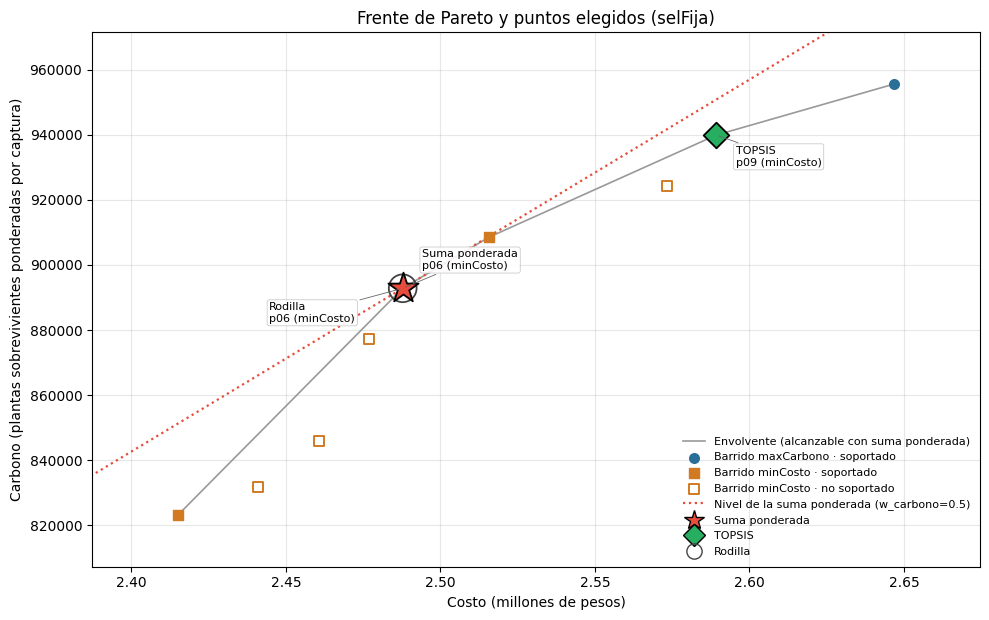

In [6]:
ESTILO_BARRIDO = {"maxCarbono": dict(marker="o", color="#2a6f97", label="Barrido maxCarbono"),
                  "minCosto":   dict(marker="s", color="#d17a22", label="Barrido minCosto")}
ESTILO_METODO = {   # marcador, tamaño, color, orden de dibujo (los más pequeños van encima de los grandes)
    "suma_ponderada": dict(marker="*", s=520, color="#e74c3c", z=6),
    "topsis":         dict(marker="D", s=170, color="#27ae60", z=7),
    "precio_carbono": dict(marker="P", s=190, color="#8e44ad", z=8),
    "rodilla":        dict(marker="o", s=400, color="none",    z=5),
}
OFFSETS = {"suma_ponderada": (14, 14), "topsis": (14, -22), "precio_carbono": (-96, 10), "rodilla": (-96, -24)}


def dibujar_elegidos(ax, dec, sel, escala_x=1e6, anotar=True):
    for k, i in sel.items():
        e, r = ESTILO_METODO[k], dec.loc[i]
        ax.scatter(r.costo / escala_x, r.carbono, marker=e["marker"], s=e["s"],
                   facecolors=e["color"], edgecolors="black" if e["color"] != "none" else "#444",
                   linewidths=1.3, zorder=e["z"] + 3)
        if anotar:
            ax.annotate(f"{ETQ[k]}\n{r.punto} ({r.barrido})", (r.costo / escala_x, r.carbono),
                        textcoords="offset points", xytext=OFFSETS[k], fontsize=8,
                        arrowprops=dict(arrowstyle="-", color="#666", lw=0.6), zorder=20,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="#bbb", lw=0.5, alpha=0.9))


def leyenda_metodos(sel):
    return [Line2D([0], [0], marker=ESTILO_METODO[k]["marker"], ls="", markersize=11 if k != "suma_ponderada" else 15,
                   markerfacecolor=ESTILO_METODO[k]["color"],
                   markeredgecolor="black" if ESTILO_METODO[k]["color"] != "none" else "#444", label=ETQ[k]) for k in sel]


def fig_frente(dec, sel, w, ruta):
    C, G = dec["costo"].to_numpy(float), dec["carbono"].to_numpy(float)
    rc, rg = max(C.max() - C.min(), 1e-9), max(G.max() - G.min(), 1e-9)
    fig, ax = plt.subplots(figsize=(10, 6.3))

    env = dec[dec["soportado"]].sort_values("costo")
    ax.plot(env["costo"] / 1e6, env["carbono"], "-", color="#999", lw=1.2, zorder=2,
            label="Envolvente (alcanzable con suma ponderada)")
    for b, sub in dec.groupby("barrido"):
        e = ESTILO_BARRIDO.get(b, dict(marker="o", color="gray", label=b))
        s_, n_ = sub[sub["soportado"]], sub[~sub["soportado"]]
        ax.scatter(s_["costo"] / 1e6, s_["carbono"], s=48, zorder=3, marker=e["marker"], color=e["color"],
                   label=f"{e['label']} · soportado")
        if len(n_):
            ax.scatter(n_["costo"] / 1e6, n_["carbono"], s=48, zorder=3, marker=e["marker"], facecolors="white",
                       edgecolors=e["color"], linewidths=1.4, label=f"{e['label']} · no soportado")

    # curva de nivel de la suma ponderada que pasa por el punto elegido
    if "suma_ponderada" in sel and 0 < w < 1:
        s0 = dec.loc[sel["suma_ponderada"], "score_ponderado"]
        cs = np.linspace(C.min() - 0.15 * rc, C.max() + 0.15 * rc, 60)
        g = G.min() + rg * (s0 - (1 - w) * (C.max() - cs) / rc) / w
        ax.plot(cs / 1e6, g, ":", color="#e74c3c", lw=1.6, zorder=2, label=f"Nivel de la suma ponderada (w_carbono={w:g})")

    dibujar_elegidos(ax, dec, sel)
    ax.set_xlim((C.min() - 0.12 * rc) / 1e6, (C.max() + 0.12 * rc) / 1e6)
    ax.set_ylim(G.min() - 0.12 * rg, G.max() + 0.12 * rg)
    ax.set_xlabel("Costo (millones de pesos)")
    ax.set_ylabel("Carbono (plantas sobrevivientes ponderadas por captura)")
    ax.set_title(f"Frente de Pareto y puntos elegidos ({mb.cfg.MODO})")
    ax.grid(alpha=0.3)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h + leyenda_metodos(sel), l + [ETQ[k] for k in sel], frameon=False, fontsize=8, loc="lower right")
    fig.tight_layout()
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()


fig_frente(dec, sel, W_CARBONO, SALIDA / "1_frente_y_elegidos.png")

### Figura 2 · Cómo decidió cada método
Cada método mide "qué tan bueno" es un punto en un espacio distinto:

- **Suma ponderada** (izquierda): costo y carbono llevados a [0, 1] con min–max; las líneas son curvas de nivel `w·z_carbono + (1-w)·z_costo`. Gana el punto en la curva más alta.
- **TOPSIS** (derecha): normalización vectorial y pesos; gana el punto más cercano al ideal (mejor carbono *y* menor costo) y más lejos del anti‑ideal. Como mide distancias, **puede elegir un punto no soportado**.

TOPSIS del notebook = TOPSIS de modelo_base ✓


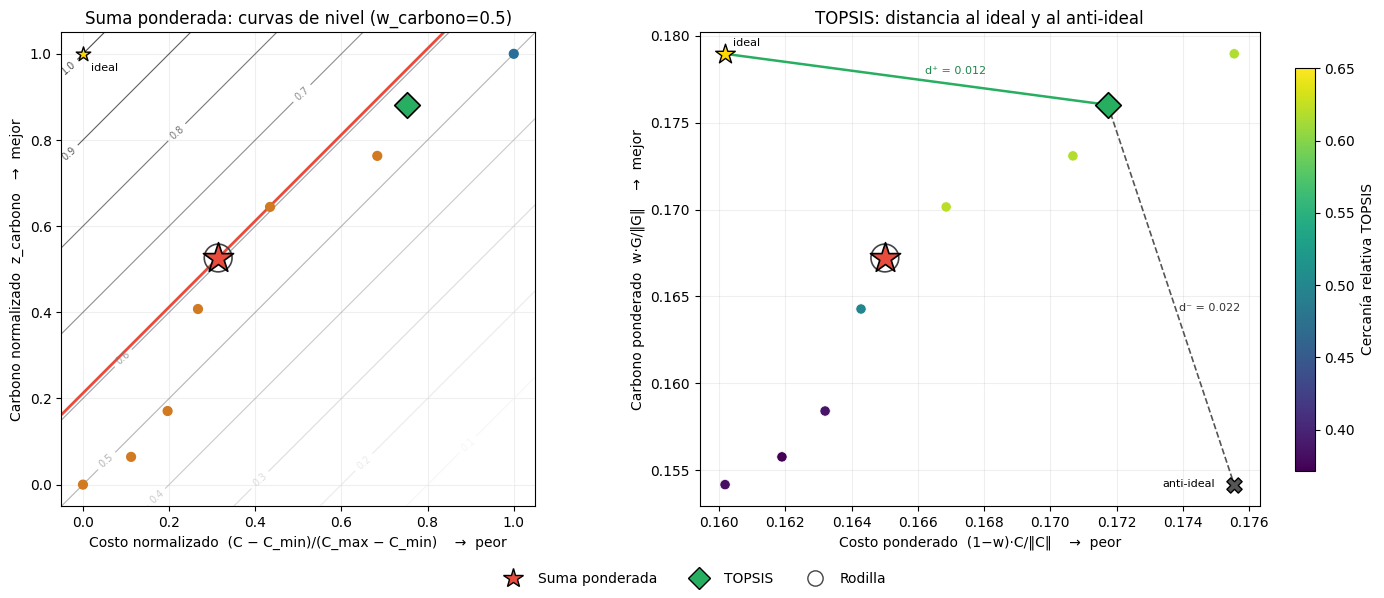

In [7]:
def topsis(C, G, w):
    # misma fórmula que mb.decision_a_posteriori (normalización vectorial, 2 criterios)
    vG, vC = w * G / np.linalg.norm(G), (1 - w) * C / np.linalg.norm(C)
    d_mas = np.sqrt((vG - vG.max()) ** 2 + (vC - vC.min()) ** 2)
    d_menos = np.sqrt((vG - vG.min()) ** 2 + (vC - vC.max()) ** 2)
    return vC, vG, d_mas, d_menos, d_menos / np.maximum(d_mas + d_menos, 1e-12)


C_, G_ = dec["costo"].to_numpy(float), dec["carbono"].to_numpy(float)
_, _, _, _, t_check = topsis(C_, G_, W_CARBONO)
assert np.allclose(t_check, dec["topsis"].to_numpy(float)), "mi TOPSIS no coincide con modelo_base: revisa la fórmula"
print("TOPSIS del notebook = TOPSIS de modelo_base ✓")


def fig_espacios(dec, sel, w, ruta):
    C, G = dec["costo"].to_numpy(float), dec["carbono"].to_numpy(float)
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))

    # --- izquierda: espacio min-max de la suma ponderada ---
    a = ax[0]
    x = 1 - dec["z_costo"].to_numpy(float)          # costo normalizado (0 = el más barato)
    y = dec["z_carbono"].to_numpy(float)
    gx, gy = np.meshgrid(np.linspace(-0.05, 1.05, 200), np.linspace(-0.05, 1.05, 200))
    score = w * gy + (1 - w) * (1 - gx)
    cs = a.contour(gx, gy, score, levels=np.linspace(0, 1, 11), cmap="Greys", linewidths=0.8, alpha=0.7)
    a.clabel(cs, fmt="%.1f", fontsize=7)
    if "suma_ponderada" in sel:
        s0 = dec.loc[sel["suma_ponderada"], "score_ponderado"]
        a.contour(gx, gy, score, levels=[s0], colors="#e74c3c", linewidths=2)
    a.scatter(x, y, c=[ESTILO_BARRIDO.get(b, {"color": "gray"})["color"] for b in dec["barrido"]], s=40, zorder=3)
    for k, i in sel.items():
        e = ESTILO_METODO[k]
        a.scatter(x[i], y[i], marker=e["marker"], s=e["s"], facecolors=e["color"],
                  edgecolors="black" if e["color"] != "none" else "#444", linewidths=1.2, zorder=e["z"] + 3)
    a.scatter([0], [1], marker="*", s=120, color="gold", edgecolors="black", zorder=9)
    a.annotate("ideal", (0, 1), textcoords="offset points", xytext=(6, -12), fontsize=8)
    a.set_xlabel("Costo normalizado  (C − C_min)/(C_max − C_min)    →  peor")
    a.set_ylabel("Carbono normalizado  z_carbono   →  mejor")
    a.set_title(f"Suma ponderada: curvas de nivel (w_carbono={w:g})")
    a.set_aspect("equal"); a.grid(alpha=0.2)

    # --- derecha: espacio ponderado de TOPSIS ---
    b = ax[1]
    vC, vG, d_mas, d_menos, ct = topsis(C, G, w)
    ideal, anti = (vC.min(), vG.max()), (vC.max(), vG.min())
    sc = b.scatter(vC, vG, c=ct, cmap="viridis", s=55, zorder=3, edgecolors="white", linewidths=0.5)
    fig.colorbar(sc, ax=b, label="Cercanía relativa TOPSIS", shrink=0.85)
    b.scatter(*ideal, marker="*", s=220, color="gold", edgecolors="black", zorder=6)
    b.scatter(*anti, marker="X", s=120, color="#555", edgecolors="black", zorder=6)
    b.annotate("ideal", ideal, textcoords="offset points", xytext=(6, 6), fontsize=8)
    b.annotate("anti‑ideal", anti, textcoords="offset points", xytext=(-52, -2), fontsize=8)
    if "topsis" in sel:
        i = sel["topsis"]
        b.plot([vC[i], ideal[0]], [vG[i], ideal[1]], "-", color="#27ae60", lw=1.8, zorder=4)
        b.plot([vC[i], anti[0]], [vG[i], anti[1]], "--", color="#555", lw=1.2, zorder=4)
        b.annotate(f"d⁺ = {d_mas[i]:.3f}", ((vC[i] + ideal[0]) / 2, (vG[i] + ideal[1]) / 2), fontsize=8,
                   textcoords="offset points", xytext=(6, 4), color="#1e8449")
        b.annotate(f"d⁻ = {d_menos[i]:.3f}", ((vC[i] + anti[0]) / 2, (vG[i] + anti[1]) / 2), fontsize=8,
                   textcoords="offset points", xytext=(6, -12), color="#333")
    for k, i in sel.items():
        e = ESTILO_METODO[k]
        b.scatter(vC[i], vG[i], marker=e["marker"], s=e["s"], facecolors=e["color"],
                  edgecolors="black" if e["color"] != "none" else "#444", linewidths=1.2, zorder=e["z"] + 3)
    b.set_xlabel("Costo ponderado  (1−w)·C/‖C‖    →  peor")
    b.set_ylabel("Carbono ponderado  w·G/‖G‖    →  mejor")
    b.set_title("TOPSIS: distancia al ideal y al anti‑ideal")
    b.grid(alpha=0.2)
    fig.legend(handles=leyenda_metodos(sel), loc="lower center", ncol=len(sel), frameon=False)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()


fig_espacios(dec, sel, W_CARBONO, SALIDA / "2_espacios_de_decision.png")

### Figura 3 · Puntaje de cada punto del frente
Barras = puntaje de cada método (ordenado por costo). La marca ▼ señala el máximo de cada uno.

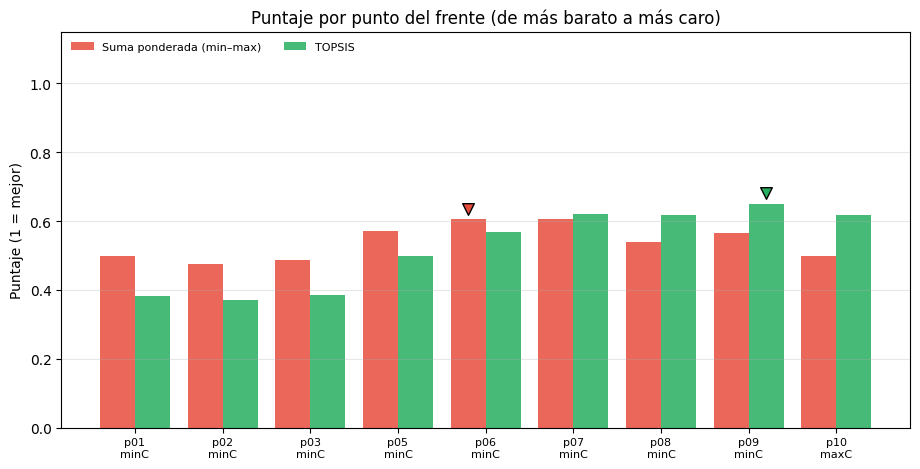

In [8]:
def fig_scores(dec, sel, ruta):
    n = len(dec)
    x = np.arange(n)
    fig, ax = plt.subplots(figsize=(max(9, 0.7 * n + 3), 4.8))
    ax.bar(x - 0.2, dec["score_ponderado"], 0.4, color="#e74c3c", alpha=0.85, label="Suma ponderada (min–max)")
    ax.bar(x + 0.2, dec["topsis"], 0.4, color="#27ae60", alpha=0.85, label="TOPSIS")
    for k, off, c in (("suma_ponderada", -0.2, "#e74c3c"), ("topsis", 0.2, "#27ae60")):
        if k in sel:
            i = sel[k]
            col = "score_ponderado" if k == "suma_ponderada" else "topsis"
            ax.scatter(i + off, dec.loc[i, col] + 0.03, marker="v", color=c, edgecolors="black", s=70, zorder=5)
    if "precio_carbono" in dec.columns:
        ax2 = ax.twinx()
        ax2.plot(x, dec["valor_neto"] / 1e6, "o--", color="#8e44ad", ms=4, lw=1, label="Valor neto p·G − C (M$)")
        ax2.set_ylabel("Valor neto (millones de pesos)", color="#8e44ad")
        if "precio_carbono" in sel:
            i = sel["precio_carbono"]
            ax2.scatter(i, dec.loc[i, "valor_neto"] / 1e6, marker="P", s=150, color="#8e44ad", edgecolors="black", zorder=6)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{r.punto}\n{'maxC' if r.barrido == 'maxCarbono' else 'minC'}" for r in dec.itertuples()], fontsize=8)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Puntaje (1 = mejor)")
    ax.set_title("Puntaje por punto del frente (de más barato a más caro)")
    ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()


fig_scores(dec, sel, SALIDA / "3_puntajes.png")

### Figura 4 · Sensibilidad al peso del carbono
¿Qué punto elegiría cada método si `w_carbono` fuera otro? La línea vertical es el peso usado. Los escalones de la suma ponderada solo caen en puntos soportados.

Suma ponderada:
  w_carbono en [0.00, 0.37] -> minCosto p01
  w_carbono en [0.38, 0.50] -> minCosto p06
  w_carbono en [0.51, 0.57] -> minCosto p07
  w_carbono en [0.58, 0.67] -> minCosto p09
  w_carbono en [0.68, 1.00] -> maxCarbono p10
TOPSIS:
  w_carbono en [0.00, 0.25] -> minCosto p01
  w_carbono en [0.26, 0.38] -> minCosto p06
  w_carbono en [0.39, 0.46] -> minCosto p07
  w_carbono en [0.47, 0.70] -> minCosto p09
  w_carbono en [0.71, 1.00] -> maxCarbono p10


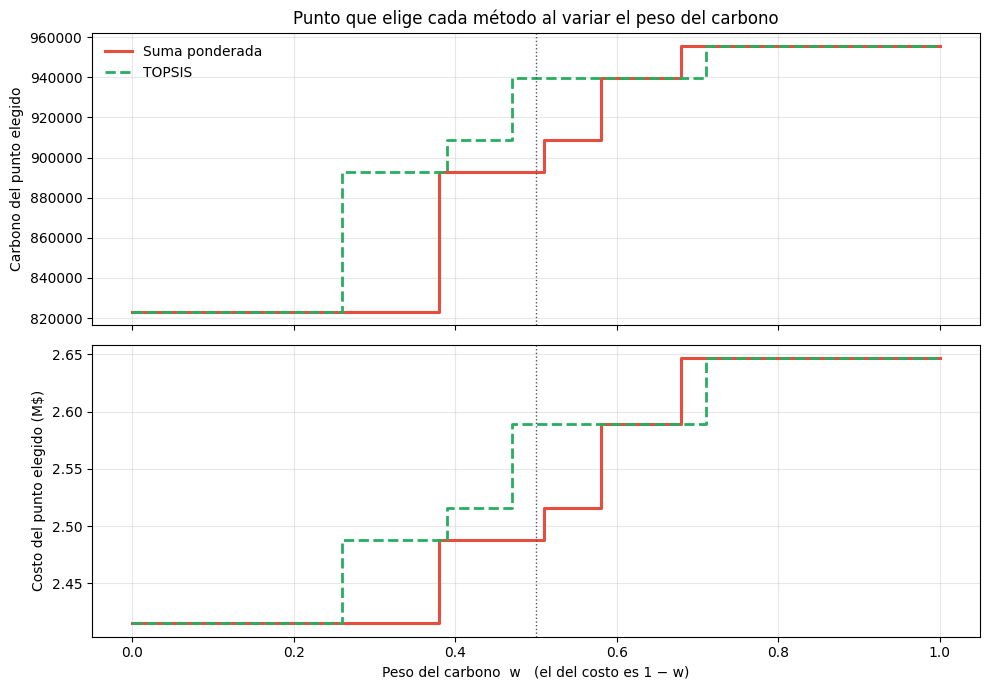

In [9]:
def barrer_pesos(dec, pasos=101):
    C, G = dec["costo"].to_numpy(float), dec["carbono"].to_numpy(float)
    zc, zg = dec["z_costo"].to_numpy(float), dec["z_carbono"].to_numpy(float)
    filas = []
    for wk in np.linspace(0, 1, pasos):
        i_ws = int(np.argmax(wk * zg + (1 - wk) * zc))
        i_tp = int(np.argmax(topsis(C, G, wk)[4]))
        filas.append({"w": wk, "i_ws": i_ws, "i_tp": i_tp})
    return pd.DataFrame(filas)


def imprimir_tramos(sd, col, nombre):
    print(f"{nombre}:")
    grupo = (sd[col] != sd[col].shift()).cumsum()
    for _, g in sd.groupby(grupo):
        r = dec.loc[g[col].iloc[0]]
        print(f"  w_carbono en [{g.w.min():.2f}, {g.w.max():.2f}] -> {r.barrido} {r.punto}")


def fig_sensibilidad(dec, sd, w, ruta):
    fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
    for a, col, esc, ylab in ((ax[0], "carbono", 1, "Carbono del punto elegido"),
                              (ax[1], "costo", 1e6, "Costo del punto elegido (M$)")):
        a.step(sd.w, dec.loc[sd.i_ws, col].to_numpy() / esc, where="post", color="#e74c3c", lw=2.2, label="Suma ponderada")
        a.step(sd.w, dec.loc[sd.i_tp, col].to_numpy() / esc, where="post", color="#27ae60", lw=2, ls="--", label="TOPSIS")
        a.axvline(w, color="#555", lw=1, ls=":")
        a.set_ylabel(ylab); a.grid(alpha=0.3)
    ax[0].legend(frameon=False)
    ax[0].set_title("Punto que elige cada método al variar el peso del carbono")
    ax[1].set_xlabel("Peso del carbono  w   (el del costo es 1 − w)")
    fig.tight_layout()
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    plt.show()


sd = barrer_pesos(dec)
imprimir_tramos(sd, "i_ws", "Suma ponderada")
imprimir_tramos(sd, "i_tp", "TOPSIS")
fig_sensibilidad(dec, sd, W_CARBONO, SALIDA / "4_sensibilidad_peso.png")

## 3. Cuadre del flujo de plantas de cada punto elegido

`compra (pedido)` → `llegada a bodega (edad 0)` → `envejece en bodega` → `se planta con edad 3–7` / `merma al cumplir 7`

Por cada punto se leen `<PREFIJO>_calendario.csv`, `<PREFIJO>_compras.csv` y `<PREFIJO>_plan_siembra.csv` de `barrido_<dirección>/`.
Un lote es `especie|vivero|d<llegada>`; al cierre del día *t* tiene edad *t − L*:

`Inventario(t) = Inventario(t−1) + Llega(t) − Plantado(t) − Merma(t)`

### Carga de los CSV

In [10]:
def cargar(carpeta: Path, prefijo: str):
    leer = lambda nombre: pd.read_csv(carpeta / f"{prefijo}_{nombre}.csv", encoding="utf-8-sig")
    cal, com, plan = leer("calendario"), leer("compras"), leer("plan_siembra")

    com = com.rename(columns={"Especie": "especie", "Comprar a": "proveedor",
                              "Día de pedido": "dia_pedido", "Día de llegada": "dia_llegada",
                              "Cantidad": "cantidad"})
    com["lote"] = com["especie"] + "|" + com["proveedor"] + "|d" + com["dia_llegada"].astype(str)
    return cal, com, plan

### Reconstrucción del inventario por lote
Lo que sigue en bodega al cierre del día en que cumple edad 7 se cuenta como merma.

In [11]:
def reconstruir(com: pd.DataFrame, plan: pd.DataFrame):
    # Para cada lote y día t (0..N_DIAS): llegada, plantado, merma e inventario al cierre.
    N, EMAX = PARAMS["N_DIAS"], PARAMS["EDAD_MAX"]
    dias = np.arange(0, N + 1)

    lotes = (com.groupby(["lote", "especie", "proveedor", "dia_llegada"], as_index=False)
                .agg(comprado=("cantidad", "sum"), dia_pedido=("dia_pedido", "min")))
    # lotes que aparecen en el plan pero no en compras (error de cuadre): se agregan con comprado=0
    faltan = set(plan["lote"]) - set(lotes["lote"])
    if faltan:
        extra = (plan[plan["lote"].isin(faltan)]
                 .groupby(["lote", "especie", "proveedor", "dia_llegada"], as_index=False).size()
                 .drop(columns="size"))
        extra["comprado"], extra["dia_pedido"] = 0, extra["dia_llegada"] - PARAMS["LEAD_TIME"]
        lotes = pd.concat([lotes, extra], ignore_index=True)
    lotes = lotes.sort_values(["especie", "dia_llegada", "proveedor"]).reset_index(drop=True)

    plant_ld = plan.pivot_table(index="lote", columns="dia_plantacion", values="plantas",
                                aggfunc="sum", fill_value=0).reindex(columns=dias, fill_value=0)
    plant_ld = plant_ld.reindex(lotes["lote"], fill_value=0)

    registros = []
    for _, r in lotes.iterrows():
        L, q = int(r.dia_llegada), float(r.comprado)
        stock = 0.0
        for t in dias:
            llega = q if t == L else 0.0
            plantado = float(plant_ld.at[r.lote, t])
            edad = t - L
            stock = stock + llega - plantado
            merma = 0.0
            if edad == EMAX and stock > TOL:
                merma, stock = stock, 0.0
            registros.append(dict(lote=r.lote, especie=r.especie, proveedor=r.proveedor,
                                  dia_llegada=L, dia=t, edad=edad, llega=llega, plantado=plantado,
                                  merma=merma, inventario=stock if edad >= 0 else 0.0))
    return lotes, pd.DataFrame(registros)

### Validaciones del flujo

In [12]:
def validar(cal, com, plan, lotes, flujo):
    # Devuelve (chk por lote, dias, cp polígono-día, lista de (estado, regla, detalle)).
    N, EMAX = PARAMS["N_DIAS"], PARAMS["EDAD_MAX"]
    out = []
    def reg(estado, regla, detalle):
        out.append((estado, regla, detalle))

    # --- por lote ---
    por_lote = (flujo.groupby("lote", as_index=False)
                     .agg(plantado=("plantado", "sum"), merma=("merma", "sum"), inv_min=("inventario", "min")))
    fin = flujo[flujo.dia == N][["lote", "inventario"]].rename(columns={"inventario": "inventario_final"})
    chk = lotes.merge(por_lote, on="lote").merge(fin, on="lote")
    chk["balance"] = chk["comprado"] - chk["plantado"] - chk["merma"] - chk["inventario_final"]
    chk["estado"] = np.select(
        [chk["inv_min"] < -TOL, chk["comprado"] == 0, chk["merma"] > TOL, chk["inventario_final"] > TOL],
        ["ERROR: inventario negativo", "ERROR: plantado sin compra", "merma", "sobra al cierre"],
        default="OK")

    neg = chk[chk.inv_min < -TOL]
    reg("OK" if neg.empty else "ERROR", "Inventario nunca negativo por lote",
        "sí" if neg.empty else f"{len(neg)} lotes plantan más de lo comprado: {list(neg.lote)[:5]}")
    sin_compra = chk[chk.comprado == 0]
    reg("OK" if sin_compra.empty else "ERROR", "Todo lote plantado tiene compra",
        "sí" if sin_compra.empty else f"{list(sin_compra.lote)}")
    no_usados = chk[(chk.comprado > 0) & (chk.plantado == 0)]
    reg("OK" if no_usados.empty else "AVISO", "Lotes comprados y nunca plantados",
        "ninguno" if no_usados.empty else f"{len(no_usados)}: {list(no_usados.lote)[:8]}")
    reg("OK" if abs(chk.balance).max() < TOL else "ERROR", "Comprado = plantado + merma + inventario final",
        f"máx |desbalance| = {abs(chk.balance).max():.3g}")
    tot_c, tot_p = chk.comprado.sum(), chk.plantado.sum()
    tot_m, tot_f = chk.merma.sum(), chk.inventario_final.sum()
    reg("OK" if tot_m < TOL else "AVISO", "Merma total", f"{tot_m:,.0f} plantas")
    reg("OK" if tot_f < TOL else "AVISO", f"Inventario al cierre del día {N}", f"{tot_f:,.0f} plantas")
    reg("INFO", "Totales", f"comprado {tot_c:,.0f} | plantado {tot_p:,.0f} | merma {tot_m:,.0f} | sobra {tot_f:,.0f}")

    # --- edades ---
    edad_calc = plan.dia_plantacion - plan.dia_llegada
    mal = plan[edad_calc != plan.edad]
    reg("OK" if mal.empty else "ERROR", "edad = día plantación - día llegada",
        "sí" if mal.empty else f"{len(mal)} filas no coinciden")
    fuera = plan[~plan.edad.isin(PARAMS["EDADES_PLANTABLES"])]
    reg("OK" if fuera.empty else "ERROR", f"Edad de plantación en {PARAMS['EDADES_PLANTABLES']}",
        "sí" if fuera.empty else f"{len(fuera)} filas fuera de rango (edades {sorted(fuera.edad.unique())})")

    # --- lead time ---
    lt = com[com.dia_llegada - com.dia_pedido != PARAMS["LEAD_TIME"]]
    reg("OK" if lt.empty else "ERROR", f"Llegada = pedido + {PARAMS['LEAD_TIME']}",
        "sí" if lt.empty else f"{len(lt)} compras con otro lead time")

    # --- por día ---
    edad_ok = (flujo.edad >= 0) & (flujo.edad < EMAX)
    dias = (flujo.assign(en_bodega=np.where(edad_ok, flujo.inventario, 0.0))
                 .groupby("dia", as_index=False)
                 .agg(llega=("llega", "sum"), plantado=("plantado", "sum"),
                      merma=("merma", "sum"), bodega=("en_bodega", "sum")))
    dias["viajes"] = np.ceil(dias.llega / PARAMS["K_CAM"] - 1e-9).astype(int)
    dias["uso_bodega_%"] = 100 * dias.bodega / CAP_BODEGA
    dias["uso_mo_%"] = 100 * dias.plantado / CAP_MO
    sobre_b = dias[dias.bodega > CAP_BODEGA + TOL]
    reg("OK" if sobre_b.empty else "ERROR", f"Bodega <= {CAP_BODEGA:,.0f} plantas",
        f"máx {dias.bodega.max():,.0f} (día {int(dias.loc[dias.bodega.idxmax(), 'dia'])})"
        + ("" if sobre_b.empty else f"; excede en días {list(sobre_b.dia)}"))
    sobre_mo = dias[dias.plantado > CAP_MO + TOL]
    reg("OK" if sobre_mo.empty else "ERROR", f"Plantado/día <= {CAP_MO:,.0f} (mano de obra)",
        f"máx {dias.plantado.max():,.0f}" + ("" if sobre_mo.empty else f"; excede en días {list(sobre_mo.dia)}"))

    # --- calendario vs plan ---
    pd_plan = plan.groupby(["dia_plantacion", "poligono"], as_index=False).plantas.sum() \
                  .rename(columns={"dia_plantacion": "dia"})
    cp = cal.merge(pd_plan, on=["dia", "poligono"], how="outer", indicator=True)
    solo_cal, solo_plan = cp[cp._merge == "left_only"], cp[cp._merge == "right_only"]
    reg("OK" if solo_cal.empty else "ERROR", "Cada (día, polígono) del calendario tiene plantas",
        "sí" if solo_cal.empty else f"faltan: {solo_cal[['dia','poligono']].values.tolist()}")
    reg("OK" if solo_plan.empty else "ERROR", "Cada (día, polígono) plantado está en el calendario",
        "sí" if solo_plan.empty else f"sobran: {solo_plan[['dia','poligono']].values.tolist()}")
    cp = cp[cp._merge == "both"].copy()
    cp["plantas_ha"] = cp.plantas / cp.ha

    # ha/día: se exige desde el primer día plantable (los días sin siembra cuentan como 0 ha)
    dias_siembra = range(cfg.PRIMER_DIA_PLANTABLE, N + 1)
    ha_dia = cal.groupby("dia").ha.sum().reindex(dias_siembra, fill_value=0.0)
    bajo = ha_dia[ha_dia < PARAMS["HA_MIN_DIA"] - 1e-4]
    reg("OK" if bajo.empty else "AVISO", f"ha/día >= {PARAMS['HA_MIN_DIA']} (días {cfg.PRIMER_DIA_PLANTABLE}–{N})",
        "sí" if bajo.empty else f"días por debajo: { {int(d): round(float(v), 3) for d, v in bajo.items()} }")
    chico = cal[cal.ha < PARAMS["HA_LOTE_MIN"] - 1e-4]
    reg("OK" if chico.empty else "ERROR", f"ha por polígono-día >= {PARAMS['HA_LOTE_MIN']}",
        "sí" if chico.empty else f"{len(chico)} filas")

    # densidad por polígono-día dentro de la banda +-BANDA
    lo, hi = (1 - PARAMS["BANDA"]) * cfg.DENS_TOTAL, (1 + PARAMS["BANDA"]) * cfg.DENS_TOTAL
    fuera_d = cp[(cp.plantas_ha < lo - 0.5) | (cp.plantas_ha > hi + 0.5)]
    reg("OK" if fuera_d.empty else "ERROR", f"Densidad por polígono-día en [{lo:.0f}, {hi:.0f}] plantas/ha",
        f"mín {cp.plantas_ha.min():.0f} | mediana {cp.plantas_ha.median():.0f} | máx {cp.plantas_ha.max():.0f}"
        + ("" if fuera_d.empty else f" | {len(fuera_d)} polígono-días fuera de la banda"))

    # cada polígono se siembra completo y con el balance de especies +-BANDA
    ha_pol = cal.groupby("poligono").ha.sum()
    incompl = {int(h): round(v - mb.HA_TODOS[int(h)], 4) for h, v in ha_pol.items() if abs(v - mb.HA_TODOS[int(h)]) > 1e-3}
    reg("OK" if not incompl else "ERROR", "Cada polígono sembrado se cubre completo (Σha = ha del polígono)",
        f"{len(ha_pol)} polígonos" if not incompl else f"diferencias (ha): {incompl}")
    esp_pol = plan.groupby(["poligono", "especie"]).plantas.sum().unstack(fill_value=0)
    malos_esp = []
    for h in esp_pol.index:
        for s in mb.ESPECIES:
            meta = mb.DENS[s] * mb.HA_TODOS[int(h)]
            v = esp_pol.at[h, s] if s in esp_pol.columns else 0
            if v < (1 - PARAMS["BANDA"]) * meta - 1 or v > (1 + PARAMS["BANDA"]) * meta + 1:
                malos_esp.append((int(h), s, int(v), round(meta, 1)))
    reg("OK" if not malos_esp else "ERROR", f"Plantas por especie y polígono dentro de ±{PARAMS['BANDA']:.0%} de la densidad",
        "sí" if not malos_esp else f"{len(malos_esp)} casos (polígono, especie, plantas, meta): {malos_esp[:4]}")

    # --- supervivencia ---
    surv = plan[abs(plan.plantas * plan.supervivencia - plan.sobrevivientes) > 1e-6]
    reg("OK" if surv.empty else "ERROR", "sobrevivientes = plantas x supervivencia",
        "sí" if surv.empty else f"{len(surv)} filas")
    return chk, dias, cp, out

### Cuadre contra la fila de la frontera
Recalcula costo y carbono **solo con los CSV del plan** y los compara con lo que la frontera (y por tanto el modelo) reporta para ese punto.

In [13]:
def _cmp(out, nombre, calculado, reportado, rel=1e-3, abs_=1.0, aviso=False):
    if reportado is None or pd.isna(reportado):
        out.append(("INFO", nombre, f"calculado {calculado:,.2f} (la frontera no trae este dato)")); return
    dif = abs(calculado - reportado)
    ok = dif <= max(abs_, rel * max(abs(reportado), 1.0))
    out.append(("OK" if ok else ("AVISO" if aviso else "ERROR"), nombre,
                f"CSV {calculado:,.2f} vs frontera {reportado:,.2f}" + ("" if ok else f" (dif {dif:,.2f})")))


def validar_contra_frontera(fila, cal, com, plan, dias):
    out = []
    g = lambda c: fila[c] if c in fila.index else None

    # compras: costo unitario por (especie, vivero) tomado de modelo_base
    precio = com.apply(lambda r: mb.COSTOS_ESPECIES.get((r.especie, r.proveedor), np.nan), axis=1)
    if precio.isna().any():
        out.append(("ERROR", "Compras a un vivero que no vende esa especie",
                    f"{com[precio.isna()][['especie','proveedor']].drop_duplicates().values.tolist()}"))
    costo_compra = float((precio.fillna(0) * com.cantidad).sum())
    plantado, merma_t = float(plan.plantas.sum()), float(dias.merma.sum())
    viajes_min = int(dias.viajes.sum())
    costo_siembra, costo_merma = cfg.C_PLANTAR * plantado, cfg.C_MERMA * merma_t

    _cmp(out, "Costo de compra", costo_compra, g("costo_compra"))
    _cmp(out, "Costo de siembra", costo_siembra, g("costo_siembra"))
    _cmp(out, "Costo de merma", costo_merma, g("costo_merma"))
    _cmp(out, "Costo de camiones (viajes mínimos)", cfg.C_CAM * viajes_min, g("costo_camion"), aviso=True)
    if g("viajes") is not None and not pd.isna(g("viajes")):
        extra = g("viajes") - viajes_min
        out.append(("OK" if extra == 0 else "AVISO", "Viajes del modelo = viajes mínimos por llegadas",
                    f"mínimos {viajes_min} | modelo {g('viajes'):.0f}"
                    + ("" if extra == 0 else f" ({extra:+.0f}: el modelo pagó viajes de más; no afecta el cuadre de plantas)")))
    costo_total = costo_compra + costo_siembra + costo_merma + cfg.C_CAM * (g("viajes") if g("viajes") is not None and not pd.isna(g("viajes")) else viajes_min)
    _cmp(out, "Costo total (compra + siembra + merma + camión)", costo_total, g("costo"))

    _cmp(out, "Carbono total", float(plan.carbono.sum()), g("carbono"))
    _cmp(out, "Plantas plantadas", plantado, g("plantado"), abs_=0.5)
    _cmp(out, "Plantas compradas", float(com.cantidad.sum()), g("comprado"), abs_=0.5)
    _cmp(out, "Merma", merma_t, g("merma"), abs_=0.5)
    _cmp(out, "Hectáreas sembradas", float(cal.ha.sum()), g("ha_total"), rel=1e-4, abs_=0.01)
    _cmp(out, "Número de polígonos", float(cal.poligono.nunique()), g("n_poligonos"), abs_=0.0)
    if g("violaciones_adyacencia") is not None and not pd.isna(g("violaciones_adyacencia")):
        v = int(g("violaciones_adyacencia"))
        out.append(("OK" if v == 0 else "ERROR", "Violaciones de adyacencia (las reportó el modelo al exportar)", str(v)))
    return out

### Figuras del cuadre

In [14]:
def _guardar(fig, ruta):
    if ruta is not None:
        fig.savefig(ruta, dpi=150, bbox_inches="tight")


def fig_resumen(dias, cal, cp, flujo, ruta=None, titulo="", mostrar=True):
    N = PARAMS["N_DIAS"]
    x = dias.dia.values
    fig, ax = plt.subplots(4, 1, figsize=(13, 13), sharex=True)

    piv = flujo.pivot_table(index="dia", columns="especie", values="llega", aggfunc="sum", fill_value=0).reindex(x, fill_value=0)
    abajo = np.zeros(len(x))
    cmap = plt.get_cmap("tab10")
    for i, s in enumerate(piv.columns):
        ax[0].bar(x, piv[s].values, bottom=abajo, color=cmap(i % 10), label=s, width=0.8)
        abajo += piv[s].values
    ax[0].set_ylabel("Plantas que llegan")
    ax[0].set_title(f"{titulo}1 · Compras: llegadas a bodega por día")
    ax[0].legend(ncol=5, fontsize=7, loc="upper right")

    ax[1].fill_between(x, dias.bodega, step="mid", alpha=0.35, color="#3b6ea5")
    ax[1].step(x, dias.bodega, where="mid", color="#3b6ea5", label="Inventario al cierre (edad 0–6)")
    ax[1].axhline(CAP_BODEGA, color="#c0392b", ls="--", label=f"Capacidad {CAP_BODEGA:,.0f}")
    if dias.merma.sum() > 0:
        ax[1].bar(x, dias.merma, color="#e67e22", label="Merma del día", width=0.5)
    ax[1].set_ylabel("Plantas")
    ax[1].set_title("2 · Almacenamiento: inventario en bodega al cierre de cada día")
    ax[1].set_ylim(0, max(CAP_BODEGA, dias.bodega.max()) * 1.2)
    ax[1].legend(fontsize=8, loc="upper left", ncol=3)

    ax[2].bar(x, dias.plantado, color="#2e8b57", width=0.8, label="Plantado")
    ax[2].axhline(CAP_MO, color="#c0392b", ls="--", label=f"Mano de obra {CAP_MO:,.0f}/día")
    ax[2].set_ylabel("Plantas")
    ax[2].set_title("3 · Plantación: plantas por día")
    ax[2].set_ylim(0, CAP_MO * 1.25)
    ax[2].legend(fontsize=8, loc="upper left", ncol=2)

    piv_h = cal.pivot_table(index="dia", columns="poligono", values="ha", aggfunc="sum", fill_value=0).reindex(x, fill_value=0)
    abajo = np.zeros(len(x))
    cmap2 = plt.get_cmap("tab20")
    for i, h in enumerate(piv_h.columns):
        v = piv_h[h].values
        ax[3].bar(x, v, bottom=abajo, color=cmap2(i % 20), width=0.8, edgecolor="white", lw=0.4)
        for xi, (b, vi) in enumerate(zip(abajo, v)):
            if vi > 0.6:
                ax[3].text(x[xi], b + vi / 2, f"P{h}", ha="center", va="center", fontsize=6.5)
        abajo += v
    ax[3].axhline(PARAMS["HA_MIN_DIA"], color="#c0392b", ls="--", label=f"Mínimo {PARAMS['HA_MIN_DIA']} ha")
    ax[3].set_ylabel("ha")
    ax[3].set_title("4 · Calendario: hectáreas por día (etiqueta = polígono)")
    ax[3].set_ylim(0, max(abajo.max(), PARAMS["HA_MIN_DIA"]) * 1.25)
    ax[3].legend(fontsize=8, loc="upper left")
    ax[3].set_xticks(x)
    ax[3].set_xlabel("Día")
    for a in ax:
        a.grid(axis="y", alpha=0.3)
        a.set_xlim(-0.6, N + 0.6)
    fig.tight_layout()
    _guardar(fig, ruta)
    plt.show() if mostrar else plt.close(fig)


def _heat(ax, M, filas, x, titulo, cmap, fmt="{:.0f}", vmax=None):
    data = np.ma.masked_where(M == 0, M)
    im = ax.imshow(data, aspect="auto", cmap=cmap, vmin=0, vmax=vmax or max(M.max(), 1),
                   extent=(x[0] - 0.5, x[-1] + 0.5, len(filas) - 0.5, -0.5))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if M[i, j] > 0:
                ax.text(x[j], i, fmt.format(M[i, j]), ha="center", va="center", fontsize=5.5,
                        color="white" if M[i, j] > 0.6 * (vmax or M.max()) else "black")
    ax.set_yticks(range(len(filas)))
    ax.set_yticklabels(filas, fontsize=8)
    ax.set_title(titulo, loc="left", fontsize=10)
    ax.set_xticks(x)
    ax.tick_params(axis="x", labelsize=7)
    ax.grid(False)
    return im


def fig_especie_dia(flujo, ruta=None, mostrar=True):
    x = np.arange(0, PARAMS["N_DIAS"] + 1)
    EMAX = PARAMS["EDAD_MAX"]
    f = flujo.copy()
    f["en_bodega"] = np.where((f.edad >= 0) & (f.edad < EMAX), f.inventario, 0.0)
    g = f.groupby(["especie", "dia"]).agg(llega=("llega", "sum"), inv=("en_bodega", "sum"),
                                          plant=("plantado", "sum"), merma=("merma", "sum"))
    especies = sorted(f.especie.unique())
    mat = lambda c: g[c].unstack("dia").reindex(index=especies, columns=x, fill_value=0).fillna(0).values

    fig, ax = plt.subplots(3, 1, figsize=(16, 13), sharex=True)
    _heat(ax[0], mat("llega"), especies, x, "LLEGA (compras que entran a bodega)", "Blues")
    _heat(ax[1], mat("inv"), especies, x, "INVENTARIO al cierre del día (edad 0–6)", "Purples")
    _heat(ax[2], mat("plant"), especies, x, "PLANTADO", "Greens")
    M = mat("merma")
    for i, j in zip(*np.nonzero(M)):
        ax[1].add_patch(Rectangle((x[j] - 0.5, i - 0.5), 1, 1, fill=False, ec="#e67e22", lw=2))
    ax[2].set_xlabel("Día")
    fig.suptitle("Flujo por especie: Inventario(t) = Inventario(t-1) + Llega(t) − Plantado(t) − Merma(t)"
                 "   (borde naranja = merma)", fontsize=11)
    fig.tight_layout()
    _guardar(fig, ruta)
    plt.show() if mostrar else plt.close(fig)


ESTADOS = ["fuera", "llega", "bodega_joven", "bodega_plantable", "agotado", "merma"]
COLORES = ["#ffffff", "#5dade2", "#d6eaf8", "#fdebd0", "#eeeeee", "#e74c3c"]


def fig_lotes(flujo, chk, ruta_pdf, mostrar=()):
    # Una página por especie; fila = lote, columna = día. Verde = plantado ese día, gris = inventario.
    x = np.arange(0, PARAMS["N_DIAS"] + 1)
    EMAX, EMIN = PARAMS["EDAD_MAX"], min(PARAMS["EDADES_PLANTABLES"])
    cmap = ListedColormap(COLORES)
    norm = BoundaryNorm(np.arange(len(ESTADOS) + 1) - 0.5, len(ESTADOS))

    with PdfPages(ruta_pdf) as pdf:
        for esp in sorted(flujo.especie.unique()):
            fe = flujo[flujo.especie == esp]
            lotes = chk[chk.especie == esp].sort_values(["dia_llegada", "proveedor"])
            nL = len(lotes)
            E = np.zeros((nL, len(x)), dtype=int)
            P, I = np.zeros((nL, len(x))), np.zeros((nL, len(x)))
            for i, lote in enumerate(lotes.lote):
                fl = fe[fe.lote == lote].set_index("dia").reindex(x)
                for j, t in enumerate(x):
                    r = fl.loc[t]
                    P[i, j], I[i, j] = r.plantado, r.inventario
                    if r.edad < 0 or r.edad > EMAX:
                        E[i, j] = 0
                    elif r.merma > TOL:
                        E[i, j] = 5
                    elif r.edad == 0:
                        E[i, j] = 1
                    elif r.inventario <= TOL and r.plantado <= TOL:
                        E[i, j] = 4
                    elif r.edad < EMIN:
                        E[i, j] = 2
                    else:
                        E[i, j] = 3

            alto = max(3.5, 0.32 * nL + 2)
            fig, ax = plt.subplots(figsize=(17, alto))
            ax.imshow(E, cmap=cmap, norm=norm, aspect="auto", extent=(x[0] - 0.5, x[-1] + 0.5, nL - 0.5, -0.5))
            for i in range(nL):
                for j in range(len(x)):
                    if P[i, j] > 0:
                        ax.text(x[j], i, f"{P[i,j]:.0f}", ha="center", va="center", fontsize=6.5, color="#145a32", fontweight="bold")
                    elif E[i, j] in (1, 2, 3) and I[i, j] > 0:
                        ax.text(x[j], i, f"{I[i,j]:.0f}", ha="center", va="center", fontsize=5.5, color="#7f8c8d")
                    elif E[i, j] == 5:
                        m_ = flujo[(flujo.lote == lotes.lote.iloc[i]) & (flujo.dia == x[j])].merma.iloc[0]
                        ax.text(x[j], i, f"✕{m_:.0f}", ha="center", va="center", fontsize=6, color="white")
            ax.set_xticks(x - 0.5, minor=True)
            ax.set_yticks(np.arange(nL) - 0.5, minor=True)
            ax.grid(which="minor", color="#cccccc", lw=0.4)
            ax.tick_params(which="minor", length=0)
            ax.set_xticks(x)
            ax.set_yticks(range(nL))
            ax.set_yticklabels([f"{r.proveedor} · d{r.dia_llegada}  (compra {r.comprado:.0f})" for r in lotes.itertuples()], fontsize=7.5)
            for i, r in enumerate(lotes.itertuples()):
                ok = r.estado == "OK"
                txt = f"plant {r.plantado:.0f} · merma {r.merma:.0f} · sobra {r.inventario_final:.0f}"
                ax.text(x[-1] + 1.0, i, ("✓ " if ok else "⚠ ") + txt, va="center", fontsize=7,
                        color="#1e8449" if ok else "#c0392b", clip_on=False)
            ax.set_xlabel("Día")
            ax.set_title(f"{esp} — cada fila es un lote (vivero · día de llegada). "
                         "Verde = plantas plantadas ese día; gris = inventario al cierre", loc="left", fontsize=10)
            leyenda = [Rectangle((0, 0), 1, 1, fc=c, ec="#999") for c in COLORES[1:]]
            ax.legend(leyenda, ["llega (edad 0)", f"en bodega, edad < {EMIN}", "en bodega, plantable", "agotado", "merma"],
                      ncol=5, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.12 if nL > 6 else -0.25), frameon=False)
            fig.tight_layout()
            fig.subplots_adjust(right=0.80)
            pdf.savefig(fig)                      # <- la versión anterior no guardaba las páginas
            plt.show() if esp in mostrar else plt.close(fig)


def fig_poligonos(cal, cp, ruta=None, mostrar=True):
    x = np.arange(0, PARAMS["N_DIAS"] + 1)
    polis = sorted(cal.poligono.unique(), key=lambda h: cal[cal.poligono == h].dia.min())
    H = cal.pivot_table(index="poligono", columns="dia", values="ha", aggfunc="sum", fill_value=0) \
           .reindex(index=polis, columns=x, fill_value=0).values
    D = cp.pivot_table(index="poligono", columns="dia", values="plantas_ha", aggfunc="mean", fill_value=0) \
          .reindex(index=polis, columns=x, fill_value=0).values
    fig, ax = plt.subplots(2, 1, figsize=(16, 0.55 * len(polis) * 2 + 2), sharex=True)
    _heat(ax[0], H, [f"P{h}  ({cal[cal.poligono==h].ha.sum():.2f} ha)" for h in polis], x,
          "Calendario: ha sembradas por polígono y día", "YlGn", fmt="{:.2f}")
    _heat(ax[1], D, [f"P{h}" for h in polis], x,
          "Densidad resultante: plantas / ha (debería ser casi constante por polígono)", "OrRd")
    ax[1].set_xlabel("Día")
    fig.tight_layout()
    _guardar(fig, ruta)
    plt.show() if mostrar else plt.close(fig)

### Ejecutar el cuadre para cada punto elegido
Si dos criterios eligieron el mismo punto, se cuadra una sola vez.

minCosto_p06  ←  elegido por: Suma ponderada, Rodilla   (173 lotes, 40 filas de calendario, 252 de plan)
[OK   ] Inventario nunca negativo por lote: sí
[OK   ] Todo lote plantado tiene compra: sí
[OK   ] Lotes comprados y nunca plantados: ninguno
[OK   ] Comprado = plantado + merma + inventario final: máx |desbalance| = 0
[OK   ] Merma total: 0 plantas
[OK   ] Inventario al cierre del día 30: 0 plantas
[INFO ] Totales: comprado 55,718 | plantado 55,718 | merma 0 | sobra 0
[OK   ] edad = día plantación - día llegada: sí
[OK   ] Edad de plantación en (3, 4, 5, 6, 7): sí
[OK   ] Llegada = pedido + 1: sí
[OK   ] Bodega <= 10,000 plantas: máx 10,000 (día 15)
[OK   ] Plantado/día <= 2,160 (mano de obra): máx 2,160
[OK   ] Cada (día, polígono) del calendario tiene plantas: sí
[OK   ] Cada (día, polígono) plantado está en el calendario: sí
[OK   ] ha/día >= 4.0 (días 4–30): sí
[OK   ] ha por polígono-día >= 0.25: sí
[OK   ] Densidad por polígono-día en [472, 576] plantas/ha: mín 472 | mediana 

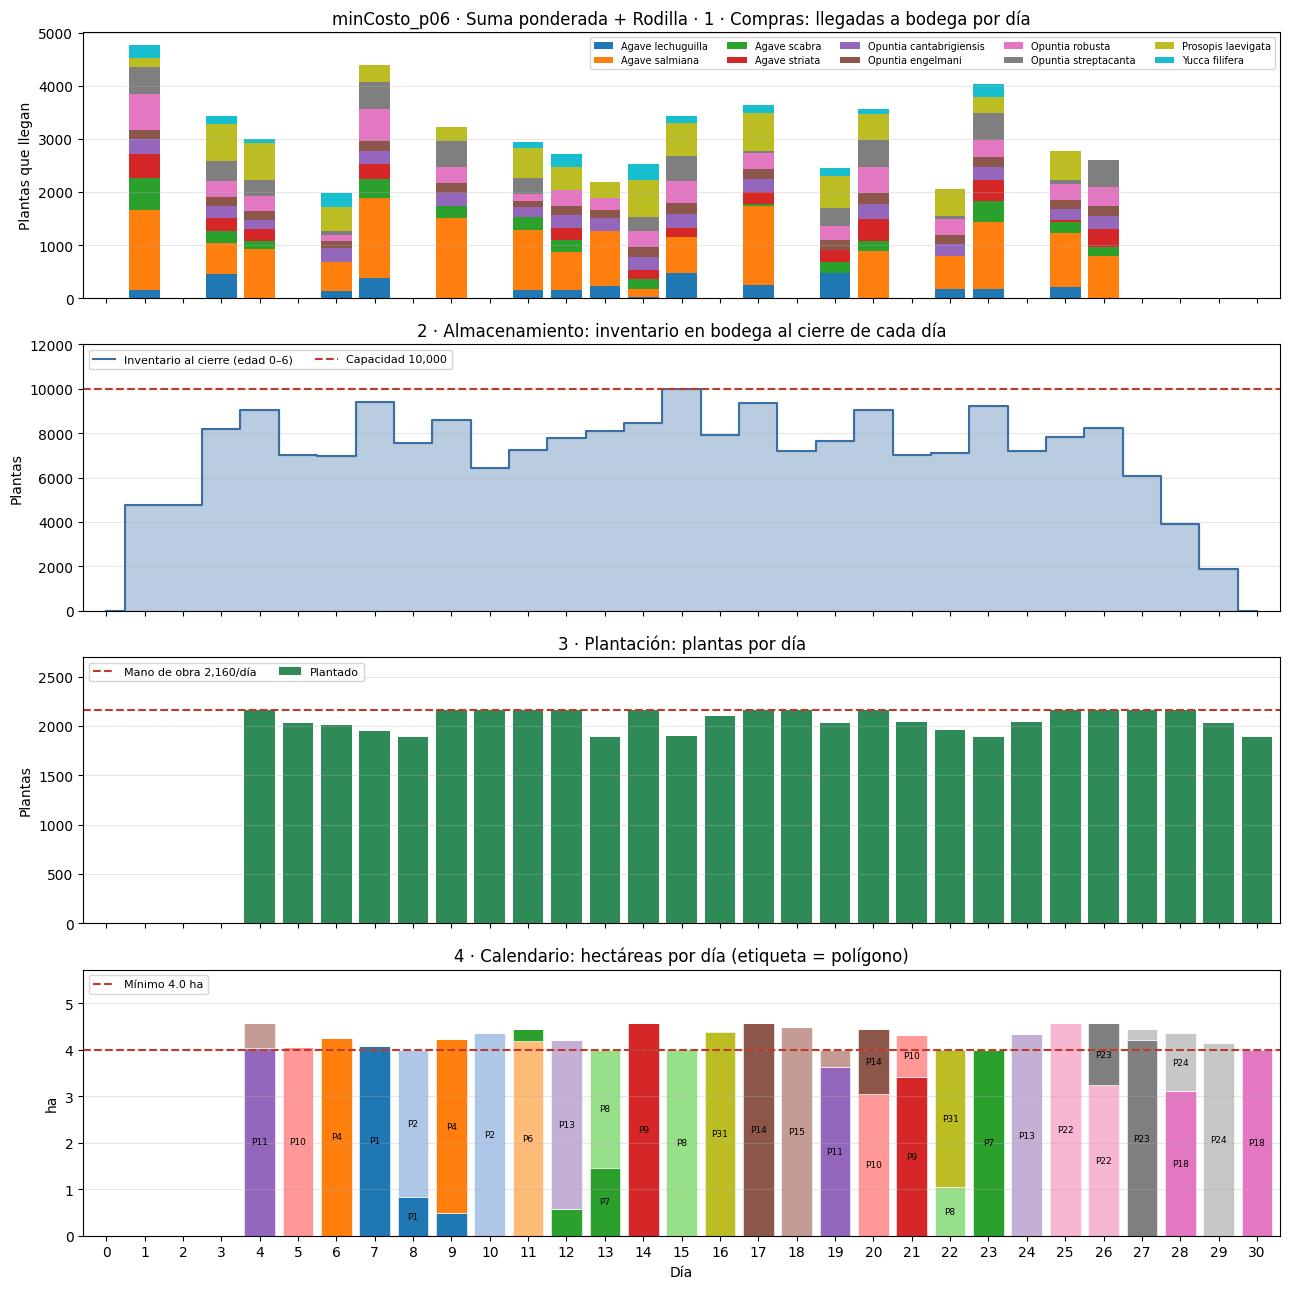

Salidas en: C:\Users\REPO\Tec2026\Cadena Suministro Reforestacion\Version4-sumaponderada\resultados_selFija\barrido_minCosto\cuadre_minCosto_p06

minCosto_p09  ←  elegido por: TOPSIS   (183 lotes, 40 filas de calendario, 242 de plan)
[OK   ] Inventario nunca negativo por lote: sí
[OK   ] Todo lote plantado tiene compra: sí
[OK   ] Lotes comprados y nunca plantados: ninguno
[OK   ] Comprado = plantado + merma + inventario final: máx |desbalance| = 0
[OK   ] Merma total: 0 plantas
[OK   ] Inventario al cierre del día 30: 0 plantas
[INFO ] Totales: comprado 57,554 | plantado 57,554 | merma 0 | sobra 0
[OK   ] edad = día plantación - día llegada: sí
[OK   ] Edad de plantación en (3, 4, 5, 6, 7): sí
[OK   ] Llegada = pedido + 1: sí
[OK   ] Bodega <= 10,000 plantas: máx 9,992 (día 7)
[OK   ] Plantado/día <= 2,160 (mano de obra): máx 2,160
[OK   ] Cada (día, polígono) del calendario tiene plantas: sí
[OK   ] Cada (día, polígono) plantado está en el calendario: sí
[OK   ] ha/día >= 4.0 (días 4

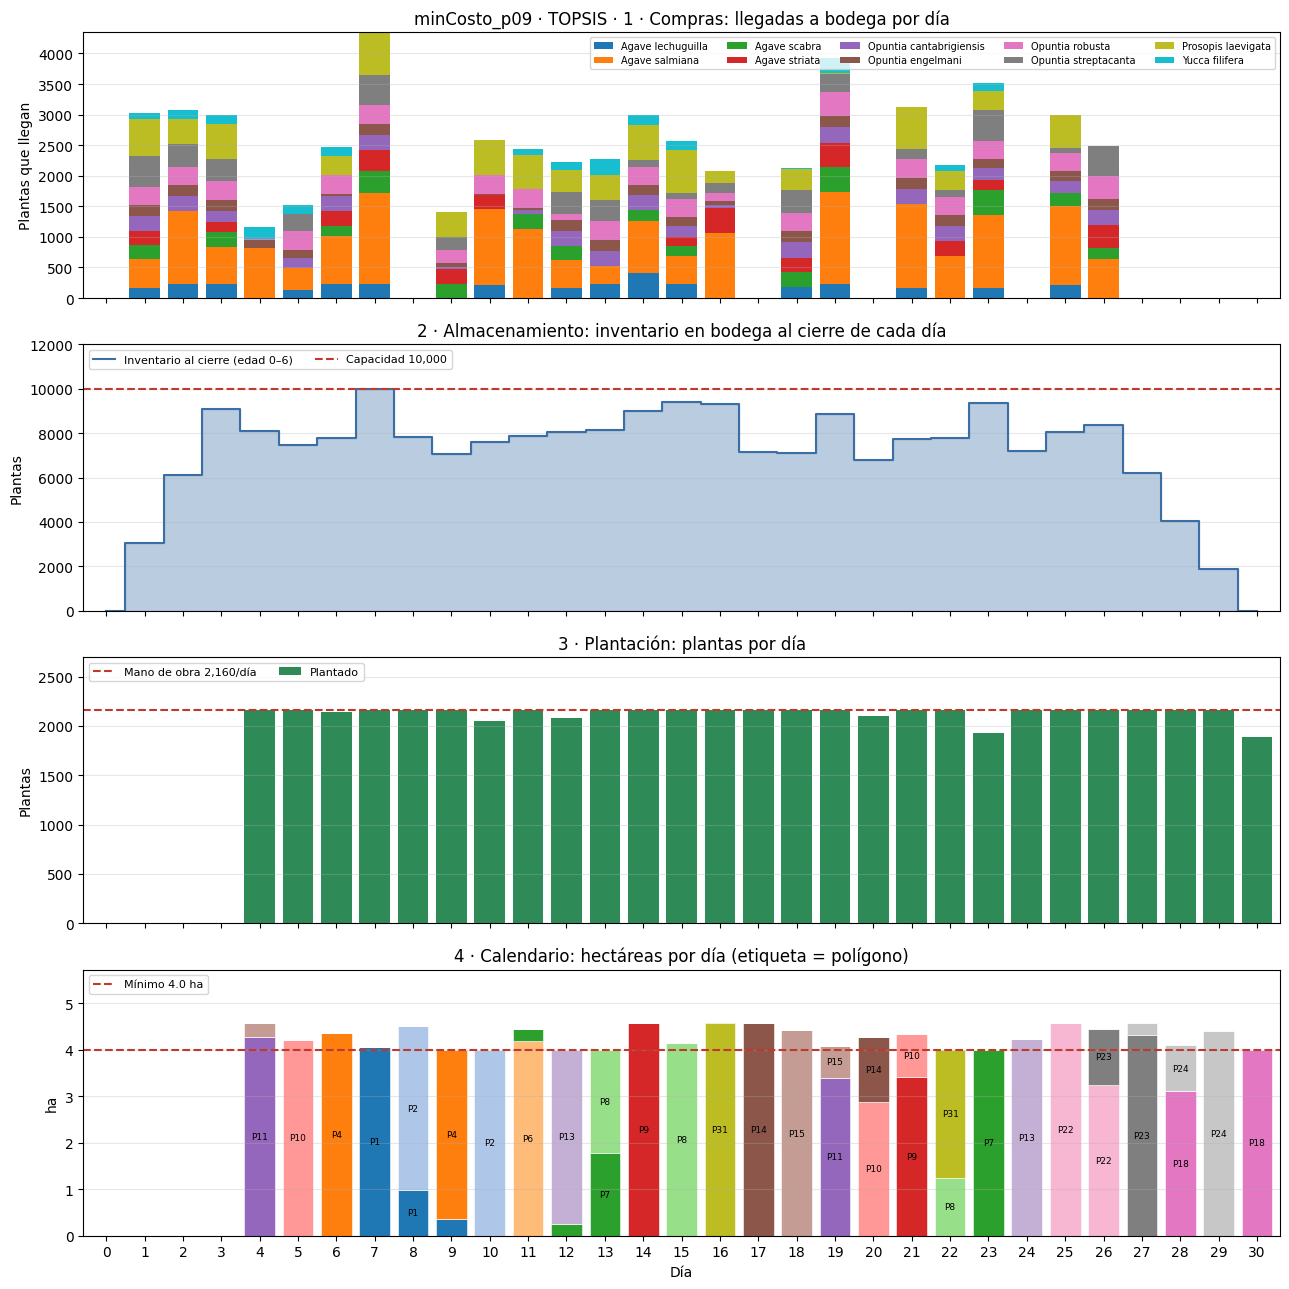

Salidas en: C:\Users\REPO\Tec2026\Cadena Suministro Reforestacion\Version4-sumaponderada\resultados_selFija\barrido_minCosto\cuadre_minCosto_p09



In [15]:
def cuadrar_punto(fila, metodos, mostrar=FIGURAS_CUADRE):
    prefijo = f"{fila.barrido}_{fila.punto}"
    carpeta = CARPETA_RESULTADOS / f"barrido_{fila.barrido}"
    salida = carpeta / f"cuadre_{prefijo}"
    salida.mkdir(exist_ok=True)

    cal, com, plan = cargar(carpeta, prefijo)
    lotes, flujo = reconstruir(com, plan)
    chk, dias, cp, out = validar(cal, com, plan, lotes, flujo)
    out += validar_contra_frontera(fila, cal, com, plan, dias)

    reporte = [f"[{e:5}] {r}: {d}" for e, r, d in out]
    chk.to_csv(salida / "checks_lotes.csv", index=False, encoding="utf-8-sig")
    dias.to_csv(salida / "checks_dias.csv", index=False, encoding="utf-8-sig")
    (salida / "reporte.txt").write_text("\n".join(reporte), encoding="utf-8")

    titulo = f"{prefijo} · " + " + ".join(ETQ[m] for m in metodos) + " · "
    print("=" * 110)
    print(f"{prefijo}  ←  elegido por: {', '.join(ETQ[m] for m in metodos)}   "
          f"({len(lotes)} lotes, {len(cal)} filas de calendario, {len(plan)} de plan)")
    print("=" * 110)
    print("\n".join(reporte))
    problemas = chk[chk.estado != "OK"]
    print(f"\nLotes con merma / sobrante / error: {len(problemas)} de {len(chk)}")
    if len(problemas):
        display(problemas)

    if "resumen" in mostrar:
        fig_resumen(dias, cal, cp, flujo, salida / "1_resumen_diario.png", titulo=titulo)
    else:
        fig_resumen(dias, cal, cp, flujo, salida / "1_resumen_diario.png", titulo=titulo, mostrar=False)
    fig_especie_dia(flujo, salida / "2_grid_especie_dia.png", mostrar="especie" in mostrar)
    fig_lotes(flujo, chk, salida / "3_grid_lotes.pdf",
              mostrar=(sorted(flujo.especie.unique()) if ESPECIES_A_MOSTRAR is None else ESPECIES_A_MOSTRAR) if "lotes" in mostrar else ())
    fig_poligonos(cal, cp, salida / "4_grid_poligonos.png", mostrar="poligonos" in mostrar)
    print(f"Salidas en: {salida.resolve()}\n")

    n = lambda e: sum(1 for x in out if x[0] == e)
    return dict(punto=prefijo, criterios=", ".join(ETQ[m] for m in metodos), ERROR=n("ERROR"), AVISO=n("AVISO"), OK=n("OK"),
                merma=float(dias.merma.sum()), sobra_al_cierre=float(chk.inventario_final.sum()),
                bodega_max=float(dias.bodega.max()), mo_max=float(dias.plantado.max()))


por_punto = {}
for k in CRITERIOS_A_CUADRAR:
    if k in sel:
        por_punto.setdefault(sel[k], []).append(k)
if not por_punto:
    print("Ningún criterio de CRITERIOS_A_CUADRAR eligió un punto.")

resumenes = []
for i, metodos in por_punto.items():
    try:
        resumenes.append(cuadrar_punto(dec.loc[i], metodos))
    except FileNotFoundError as e:
        print(f"No se encontró un archivo del punto {dec.loc[i, 'barrido']}_{dec.loc[i, 'punto']}: {e.filename}\n")

## 4. Resumen de cuadres

In [18]:
if resumenes:
    resumen = pd.DataFrame(resumenes)
    estilo = resumen.style
    pintar = getattr(estilo, "map", None) or estilo.applymap      # Styler.map es de pandas >= 2.1; antes era applymap
    estilo = pintar(lambda v: "background-color:#f5b7b1" if v > 0 else "", subset=["ERROR"])
    pintar = getattr(estilo, "map", None) or estilo.applymap
    display(pintar(lambda v: "background-color:#fcf3cf" if v > 0 else "", subset=["AVISO"]))
    resumen.to_csv(SALIDA / "resumen_cuadres.csv", index=False, encoding="utf-8-sig")
    print("Todos los puntos cuadran ✓" if (resumen.ERROR == 0).all() else "⚠ Hay puntos con ERROR: revisa su reporte arriba.")
print("Salidas de la decisión en:", SALIDA.resolve())

,punto,criterios,ERROR,AVISO,OK,merma,sobra_al_cierre,bodega_max,mo_max
0,minCosto_p06,"Suma ponderada, Rodilla",0,0,32,0.000000,0.000000,10000.000000,2160.000000
1,minCosto_p09,TOPSIS,0,0,32,0.000000,0.000000,9992.000000,2160.000000


Todos los puntos cuadran ✓
Salidas de la decisión en: C:\Users\REPO\Tec2026\Cadena Suministro Reforestacion\Version4-sumaponderada\resultados_selFija\validacion_decision
